**Disclaimer**: this notebook's compatibility with StatsBomb event data 4.0.0 was last checked on December 30th, 2023.

In [1]:
import os
import warnings
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
pd.set_option('display.max_columns', None)
warnings.simplefilter(action='ignore', category=pd.errors.PerformanceWarning)
warnings.filterwarnings(action="ignore", message="credentials were not supplied. open data access only")
warnings.filterwarnings(action="ignore", category=FutureWarning, module='socceraction.data.statsbomb.loader')
import tqdm
import statsmodels.formula.api as smf

In [2]:
%load_ext autoreload
%autoreload 2
from socceraction.data.statsbomb import StatsBombLoader
import socceraction.spadl as spadl

## Set up the StatsBombLoader

In [5]:
# Use this if you want to use the free public statsbomb data
# or provide credentials to access the API
API = StatsBombLoader(getter="remote", creds={"user": None, "passwd": None})

In [4]:
# # Uncomment the code below if you have a local folder on your computer with statsbomb data
datafolder = r"E:\Vscodeproject\data-stats\statsbomb\data"
SBL = StatsBombLoader(root=datafolder, getter="local")

In [6]:
# View all available competitions
competitions = API.competitions()
set(competitions.competition_name)

{'1. Bundesliga',
 'African Cup of Nations',
 'Champions League',
 'Copa America',
 'Copa del Rey',
 "FA Women's Super League",
 'FIFA U20 World Cup',
 'FIFA World Cup',
 'Indian Super league',
 'La Liga',
 'Liga Profesional',
 'Ligue 1',
 'Major League Soccer',
 'NWSL',
 'North American League',
 'Premier League',
 'Serie A',
 'UEFA Euro',
 'UEFA Europa League',
 "UEFA Women's Euro",
 "Women's World Cup"}

In [7]:
# Fifa world cup
selected_competitions = competitions[
    # ((competitions.competition_name == "UEFA Women's Euro") & (competitions.season_name.isin(["2022", "2025"])))
    ((competitions.competition_name == "UEFA Euro") & (competitions.season_name.isin(["2020", "2024"])))
    # ((competitions.competition_name == "Women's World Cup") & (competitions.season_name == "2019"))]
    |((competitions.competition_name == "FIFA World Cup") & (competitions.season_name == "2022"))]
    

# # Messi data
# selected_competitions = competitions[competitions.competition_name == "La Liga"]

# # FA Women's Super League
# selected_competitions = competitions[competitions.competition_name == "FA Women's Super League"]

selected_competitions

,season_id,competition_id,competition_name,country_name,competition_gender,season_name
29,106,43,FIFA World Cup,International,male,2022
68,282,55,UEFA Euro,Europe,male,2024
69,43,55,UEFA Euro,Europe,male,2020


In [8]:
# Get games from all selected competitions
games = pd.concat([
    API.games(row.competition_id, row.season_id)
    for row in selected_competitions.itertuples()
])
games[["game_id", "home_team_id", "away_team_id", "game_date", "home_score", "away_score"]]

,game_id,home_team_id,away_team_id,game_date,home_score,away_score
0,3857256,786,773,2022-12-02 21:00:00,2,3
1,3869151,779,792,2022-12-03 21:00:00,2,1
2,3857257,792,776,2022-11-30 17:00:00,1,0
3,3857258,781,786,2022-11-24 21:00:00,2,0
4,3857288,777,792,2022-11-26 12:00:00,0,1
...,...,...,...,...,...,...
46,3788742,776,1835,2021-06-12 18:00:00,0,1
47,3788775,908,772,2021-06-23 18:00:00,0,5
48,3788776,790,789,2021-06-23 18:00:00,3,2
49,3788743,782,796,2021-06-12 21:00:00,3,0


In [ ]:
df = API.events(game_id= 3788744, load_360= True) #[3845506, 3835342, 3835338]
# rows = df[df["possession"] == 26]
# print(rows)
rows = df[df["type_name"] == "Goal Keeper"]
rows
# df.type_name.unique()
# df.extra
# pass_shot_mask = df['extra'].apply(lambda x: 'pass' in x or 'shot' in x if isinstance(x, dict) else False)
# pass_shot_df = df[pass_shot_mask]
# # df.head(40)
#         "Pass", "Carry", "Clearance", "Dribble", "Shot", 
#         "Goal Keeper", "Interception"

In [ ]:
# 相对路径
spadl_h5 = "../data/women-statsbomb.h5"

# 读取 h5 文件所有 key
with pd.HDFStore(spadl_h5, mode="r") as store:
    print("📌 HDF5 keys:", store.keys())

    # 读取比赛基本信息
    games = store["games"]
    print(f"\n📌 共 {len(games)} 场比赛\n")

    print("===== 所有比赛基本信息 =====")
    display(games)

# 遍历每场比赛并读取:
events_dict = {}
teams_dict = {}
players_dict = {}

## Load and convert match data

In [9]:
games_verbose = tqdm.tqdm(list(games.itertuples()), desc="Loading game data")
teams, players = [], []
events = {}
# actions = {}

for game in games_verbose:
        # load data
        teams.append(API.teams(game.game_id))
        players.append(API.players(game.game_id))
        events[game.game_id] = API.events(game.game_id, load_360=True)
        # convert data
        # actions[game.game_id] = spadl.statsbomb.convert_to_actions(
        #     events, 
        #     home_team_id=game.home_team_id,
        #     xy_fidelity_version=1,
        #     shot_fidelity_version=1
        # )

teams = pd.concat(teams).drop_duplicates(subset="team_id")
players = pd.concat(players)

Loading game data: 100%|██████████| 166/166 [04:18<00:00,  1.56s/it]


## Store converted spadl data in a h5-file

In [10]:
datafolder = "../data"

if not os.path.exists(datafolder):
    os.mkdir(datafolder)
    print(f"Directory {datafolder} created.")

spadl_h5 = os.path.join(datafolder, "men-statsbomb.h5")

# Store all spadl data in h5-file
with pd.HDFStore(spadl_h5) as spadlstore:
    spadlstore["competitions"] = selected_competitions
    spadlstore["games"] = games
    spadlstore["teams"] = teams
    spadlstore["players"] = players[['player_id', 'player_name', 'nickname']].drop_duplicates(subset='player_id')
    spadlstore["player_games"] = players[['player_id', 'game_id', 'team_id', 'is_starter', 'starting_position_id', 'starting_position_name', 'minutes_played']]
    # for game_id in actions.keys():
    #     spadlstore[f"actions/game_{game_id}"] = actions[game_id]
    for game_id in events.keys():
        spadlstore[f"events/game_{game_id}"] = events[game_id]

### 1.CALCULATE VARIABLE(number of team passes per minute of possession) - Wyscout

In [3]:
def compute_and_plot_pace(events, home_team_id, away_team_id, min_duration_sec=3):
    """
    events: 一场比赛的事件表
    home_team_id, away_team_id: 用于确定主客队
    """

    filtered = events[
        ~events["type_name"].isin(["Starting XI", "Half Start", "Half End"])
    ].copy()

    # duration 确保为 float
    filtered["duration"] = filtered["duration"].astype(float)

    # ----------- 计算 possession duration -----------
    possession_duration = filtered.groupby("possession")["duration"].sum()

    # ----------- 筛掉 duration < min_duration_sec 的 possession -----------
    valid_possessions = possession_duration[possession_duration >= min_duration_sec].index

    filtered = filtered[filtered["possession"].isin(valid_possessions)]

    # 确保 timestamp 转化为秒
    if not pd.api.types.is_numeric_dtype(filtered["duration"]):
        filtered["duration"] = filtered["duration"].astype(float)

    # ----------- 计算每个 possession 的时间（分钟） -----------
    possession_time = (
        filtered.groupby("possession")["duration"].sum() / 60.0  # 转分钟
    )

    # ----------- 计算每个 possession 的传球数量 -----------
    passes = filtered[filtered["type_name"] == "Pass"]
    possession_passes = passes.groupby("possession")["event_id"].count()

    # ----------- 比赛节奏 = 传球数 / 控球分钟 -----------
    pace = (possession_passes / possession_time).fillna(0)

    # ----------- 合并球队信息 -----------
    team_of_possession = filtered.groupby("possession")["possession_team_id"].first()

    pace_df = pd.DataFrame({
        "pace": pace,
        "team_id": team_of_possession
    }).reset_index()

    # ----------- 分主客队 -----------
    home_pace = pace_df[pace_df["team_id"] == home_team_id]
    away_pace = pace_df[pace_df["team_id"] == away_team_id]

    # ----------- 可视化-----------
    # plt.figure(figsize=(14, 5))
    # plt.plot(home_pace["possession"], home_pace["pace"], marker="o", color="red", label="Home Team")
    # plt.plot(away_pace["possession"], away_pace["pace"], marker="o", color="blue", label="Away Team")

    # plt.xlabel("Possession ID")
    # plt.ylabel("Passes per Minute of Possession")
    # plt.title("Match Tempo: Passes per Minute of Possession")
    # plt.legend()
    # plt.grid(True)
    # plt.tight_layout()
    # plt.show()

    return pace_df


### visualization

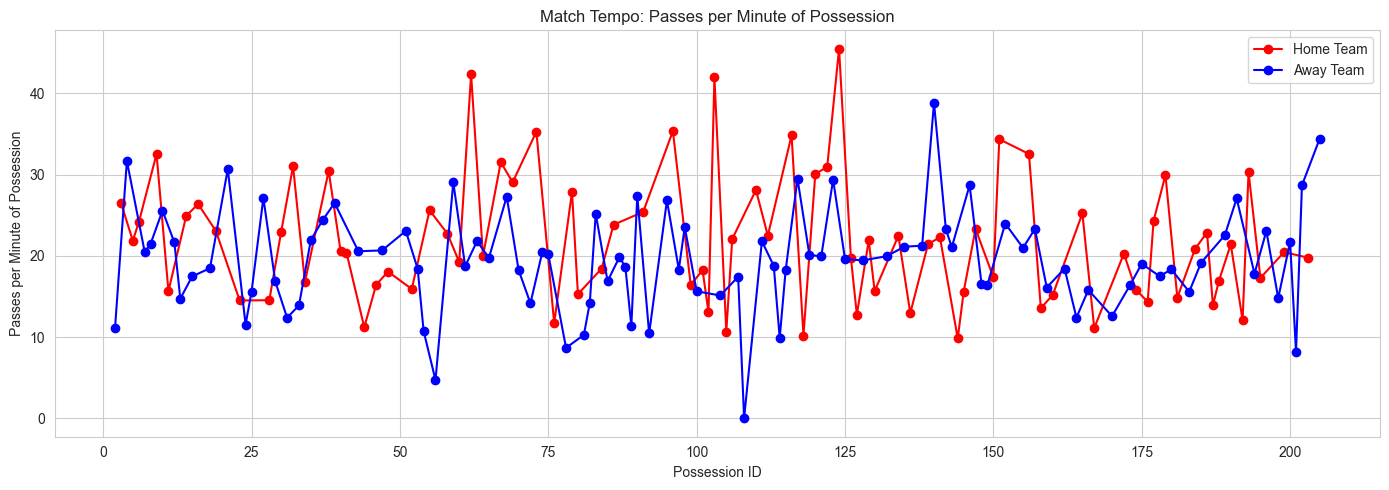

In [22]:
game_id = 3893793
df = API.events(game_id=game_id, load_360=True)

g = games.loc[games["game_id"] == game_id].iloc[0]
home_team_id = g["home_team_id"]
away_team_id = g["away_team_id"]

pace_df = compute_and_plot_pace(df, home_team_id, away_team_id)


In [ ]:
#2. 可视化 (Visualizations)
import seaborn as sns
sns.set_style("whitegrid")
plt.rcParams['figure.figsize'] = (16, 10)

# 创建子图
fig, axes = plt.subplots(2, 3, figsize=(18, 10))
fig.suptitle('Match Pace Deep Analysis', fontsize=16, fontweight='bold')

# --- 图1: 箱线图对比 (Box Plot Comparison) ---
ax1 = axes[0, 0]
pace_df_plot = pace_df.copy()
pace_df_plot['team'] = pace_df_plot['team_id'].apply(
    lambda x: 'Home Team' if x == home_team_id else 'Away Team'
)
sns.boxplot(data=pace_df_plot, x='team', y='pace', ax=ax1, palette=['red', 'blue'])
ax1.set_title('Pace Distribution Comparison', fontweight='bold')
ax1.set_ylabel('Passes per Minute')
ax1.set_xlabel('')

# --- 图2: 小提琴图 (Violin Plot) ---
ax2 = axes[0, 1]
sns.violinplot(data=pace_df_plot, x='team', y='pace', ax=ax2, palette=['red', 'blue'])
ax2.set_title('Pace Density Distribution', fontweight='bold')
ax2.set_ylabel('Passes per Minute')
ax2.set_xlabel('')

# --- 图3: 直方图 (Histogram) ---
ax3 = axes[0, 2]
home_pace_values = pace_df[pace_df['team_id'] == home_team_id]['pace']
away_pace_values = pace_df[pace_df['team_id'] == away_team_id]['pace']
ax3.hist(home_pace_values, bins=20, alpha=0.6, color='red', label='Home Team')
ax3.hist(away_pace_values, bins=20, alpha=0.6, color='blue', label='Away Team')
ax3.set_title('Pace Frequency Distribution', fontweight='bold')
ax3.set_xlabel('Passes per Minute')
ax3.set_ylabel('Frequency')
ax3.legend()

# --- 图4: 累积分布函数 (Cumulative Distribution) ---
ax4 = axes[1, 0]
home_sorted = sorted(home_pace_values)
away_sorted = sorted(away_pace_values)
ax4.plot(home_sorted, range(1, len(home_sorted) + 1), color='red', label='Home Team', linewidth=2)
ax4.plot(away_sorted, range(1, len(away_sorted) + 1), color='blue', label='Away Team', linewidth=2)
ax4.set_title('Cumulative Distribution', fontweight='bold')
ax4.set_xlabel('Passes per Minute')
ax4.set_ylabel('Cumulative Count')
ax4.legend()
ax4.grid(True, alpha=0.3)

# --- 图5: 移动平均节奏 (Moving Average Pace) ---
ax5 = axes[1, 1]
home_data = pace_df[pace_df['team_id'] == home_team_id].sort_values('possession')
away_data = pace_df[pace_df['team_id'] == away_team_id].sort_values('possession')

window = 5  # 5回合移动平均
if len(home_data) >= window:
    home_ma = home_data['pace'].rolling(window=window, center=True).mean()
    ax5.plot(home_data['possession'], home_ma, color='red', linewidth=2, label=f'Home (MA-{window})')
if len(away_data) >= window:
    away_ma = away_data['pace'].rolling(window=window, center=True).mean()
    ax5.plot(away_data['possession'], away_ma, color='blue', linewidth=2, label=f'Away (MA-{window})')

ax5.set_title(f'{window}-Possession MA', fontweight='bold')
ax5.set_xlabel('Possession ID')
ax5.set_ylabel('Passes per Minute (MA)')
ax5.legend()
ax5.grid(True, alpha=0.3)

# --- 图6: 节奏波动性对比 (Pace Variability) ---
ax6 = axes[1, 2]
variability_data = pd.DataFrame({
    'Team': ['Home Team', 'Away Team'],
    'Mean': [home_pace_values.mean(), away_pace_values.mean()],
    'Std': [home_pace_values.std(), away_pace_values.std()],
    'CV': [home_pace_values.std()/home_pace_values.mean()*100, 
           away_pace_values.std()/away_pace_values.mean()*100]
})

x_pos = range(len(variability_data))
ax6.bar(x_pos, variability_data['CV'], color=['red', 'blue'], alpha=0.7)
ax6.set_title('Coefficient of Variation %', fontweight='bold')
ax6.set_ylabel('CV (%)')
ax6.set_xticks(x_pos)
ax6.set_xticklabels(variability_data['Team'])
ax6.grid(True, alpha=0.3, axis='y')

# 添加数值标签
for i, v in enumerate(variability_data['CV']):
    ax6.text(i, v + 1, f'{v:.1f}%', ha='center', fontweight='bold')

plt.tight_layout()
plt.show()

### 2.calculate the amount of time a player takes to play a pass after gaining control of the - (Bransen & Davis, 2025)

In [4]:
def plot_ball_action_speed(events, home_team_id, away_team_id):
    """
    按照 Bransen & Davis 方法计算传球速度
    PoP(ai) = Tai - Tai-1
    Tai: 当前球员传球时间（球离脚）
    Tai-1: 上一个队友传球时间（球离脚）
    """
    df = events.copy().reset_index(drop=True)

    # 确保时间戳格式正确
    if not pd.api.types.is_timedelta64_dtype(df["timestamp"]):
        df["timestamp"] = pd.to_timedelta(df["timestamp"])

    results = []

    # 1. 筛选所有传球事件
    pass_events = df[df["type_name"] == "Pass"].copy()

    for idx, current_pass in pass_events.iterrows():
        current_player_id = current_pass["player_id"]
        current_team_id = current_pass["team_id"]
        current_possession = current_pass["possession"]
        current_time = current_pass["timestamp"]  # Tai

        # 2. 往前找上一个**同队队友**的传球事件
        previous_events = df[
            (df.index < idx) & 
            (df["possession"] == current_possession) 
        ]
        
        if len(previous_events) == 0:
            continue

        # 情况1：队友的传球
        teammate_passes = previous_events[
            (previous_events["type_name"] == "Pass") &
            (previous_events["team_id"] == current_team_id) &
            (previous_events["player_id"] != current_player_id)
        ]

        # 情况2：当前球员自己的拦截
        player_interceptions = previous_events[
            (previous_events["type_name"] == "Interception") &
            (previous_events["player_id"] == current_player_id)
        ]

        # 合并两种情况，取最近的一个
        valid_previous = pd.concat([teammate_passes, player_interceptions])
        
        if len(valid_previous) > 0:
            previous_action = valid_previous.iloc[-1]  # 取最近的一个
            previous_time = previous_action["timestamp"]  # Tai-1

            # 计算 PoP = Tai - Tai-1
            delta = (current_time - previous_time).total_seconds()

            # 过滤异常值（合理范围：0-30秒）
            if 0 <= delta <= 30:
                results.append({
                    "player_id": current_player_id,
                    "team_id": current_team_id,
                    "possession": current_possession,
                    "previous_action": previous_action["type_name"],
                    "previous_time": previous_time,
                    "current_time": current_time,
                    "time_to_pass": delta,
                    "match_time_min": current_pass["minute"] + current_pass["second"] / 60
                })
    action_speed_df = pd.DataFrame(results)

    # if len(action_speed_df) > 0:
    #     print(f"平均 PoP: {action_speed_df['time_to_pass'].mean():.2f} 秒")
    #     print(f"中位数 PoP: {action_speed_df['time_to_pass'].median():.2f} 秒")
    #     print(f"\n前一个动作类型分布：")
    #     print(action_speed_df['previous_action'].value_counts())

    # # 可视化（可选）
    # plt.figure(figsize=(14,5))

    # # 主队
    # home_df = action_speed_df[action_speed_df["team_id"] == home_team_id]
    # plt.scatter(home_df["match_time_min"], home_df["time_to_pass"], 
    #             color="red", label="Home Team", alpha=0.6)

    # # 客队
    # away_df = action_speed_df[action_speed_df["team_id"] == away_team_id]
    # plt.scatter(away_df["match_time_min"], away_df["time_to_pass"], 
    #             color="blue", label="Away Team", alpha=0.6)

    # plt.xlabel("Match Time (min)")
    # plt.ylabel("Time to Pass (s)")
    # plt.title("Time between Teammate Passes (Bransen & Davis Method)")
    # plt.legend()
    # plt.grid(True)
    # plt.tight_layout()
    # plt.show()

    return action_speed_df

In [23]:
game_id = 3893793

# 获取事件表
df = API.events(game_id=game_id, load_360=True)

# 自动查找主客队 ID
g = games.loc[games["game_id"] == game_id].iloc[0]
home_team_id = g["home_team_id"]
away_team_id = g["away_team_id"]

# 计算并可视化
action_speed_df = plot_ball_action_speed(df, home_team_id, away_team_id)


平均 PoP: 3.44 秒
中位数 PoP: 2.90 秒

前一个动作类型分布：
previous_action
Pass            839
Interception     10
Name: count, dtype: int64


### 3.calculate meters per second per touch - Hamilton (2013) 

In [5]:
def compute_possession_tempo(events, home_team_id, away_team_id):
    """
    计算每次控球的平均球速：p_i = dist / (k * t)
    - dist: 球移动总距离 (meters)
    - k: 触球次数
    - t: 控球持续时间 (seconds)
    
    - Pass/Shot/Carry: 使用 end_location 计算实际传球/射门/带球距离
    - 其他事件: 使用相邻事件位置差计算距离
    """
    df = events.copy()

    # 只保留触球的事件
    touch_types = {
        "Pass", "Carry", "Clearance", "Dribble", "Shot", 
        "Goal Keeper", "Interception"
    }

    # 转换location列为X,Y
    df["x"] = df["location"].apply(lambda loc: loc[0] if isinstance(loc, list) else np.nan)
    df["y"] = df["location"].apply(lambda loc: loc[1] if isinstance(loc, list) else np.nan)

    def parse_sub(extra, event_type):
        key = {"Pass": "pass", "Carry": "carry", "Shot": "shot"}.get(event_type, "")
        return extra.get(key, {}) if isinstance(extra, dict) and key else {}

    # 按 possession 和 possession_team_id 分组
    tempo_list = []
    poss_team_col = "possession_team_id" if "possession_team_id" in df.columns else "team_id"
    
    for (pid, team_id), group in df.groupby(["possession", poss_team_col], sort=False):
        # 仅保留触球事件并去除 NaN 坐标
        h = group[group["type_name"].isin(touch_types)].copy()
        h = h.dropna(subset=["x", "y"]).reset_index(drop=True)

        # 触球次数 k
        k = len(h)
        if k < 2:
            continue  # 至少两次触球才有意义

        # 控球持续时间 t (seconds)
        first_time = h["minute"].iloc[0] * 60 + h["second"].iloc[0]
        last_time = h["minute"].iloc[-1] * 60 + h["second"].iloc[-1]
        t = last_time - first_time
        
        if t <= 0:
            continue  # 时间必须大于0

        # 对防守方（非控球方）的动作做坐标翻转
        opp_h = (h["team_id"] != team_id).to_numpy()
        h["x_u"] = np.where(opp_h, 120 - h["x"], h["x"])
        h["y_u"] = np.where(opp_h,  80 - h["y"], h["y"])

        # 距离计算
        total_dist = 0.0
        for i in range(k):
            event_type = h.loc[i, 'type_name']
            
            # 对于 Pass/Shot/Carry，使用 end_location
            if event_type in ('Pass', 'Shot', 'Carry'):
                sub = parse_sub(h.loc[i, 'extra'], event_type)
                end = sub.get("end_location")
                if isinstance(end, list) and len(end) >= 2:
                    dx = end[0] - h.loc[i, 'x']
                    dy = end[1] - h.loc[i, 'y']
                    total_dist += float(np.hypot(dx, dy))
            
            # 对于其他事件，使用相邻事件位置差
            elif i < k - 1:
                dx = h.loc[i+1, 'x_u'] - h.loc[i, 'x_u']
                dy = h.loc[i+1, 'y_u'] - h.loc[i, 'y_u']
                total_dist += float(np.hypot(dx, dy))

        # 计算 p_i = dist / (k * t)
        p_i = total_dist / (k * t)

        # 记录数据
        match_time = h["minute"].iloc[0] + h["second"].iloc[0] / 60

        tempo_list.append({
            "possession": pid,
            "team_id": team_id,
            "total_distance": total_dist,
            "n_touches": k,
            "duration_sec": t,
            "tempo_m_per_touch_per_sec": p_i,  
            "match_time_min": match_time
        })

    tempo_df = pd.DataFrame(tempo_list)

    # 计算全场平均节奏 P
    # if len(tempo_df) > 0:
    #     P_overall = tempo_df["tempo_m_per_touch_per_sec"].mean()
    #     P_home = tempo_df[tempo_df["team_id"] == home_team_id]["tempo_m_per_touch_per_sec"].mean()
    #     P_away = tempo_df[tempo_df["team_id"] == away_team_id]["tempo_m_per_touch_per_sec"].mean()
    #     
    #     print(f"Overall Average Tempo P: {P_overall:.3f} m/(touch·sec)")
    #     print(f"Home Team Average Tempo: {P_home:.3f} m/(touch·sec)")
    #     print(f"Away Team Average Tempo: {P_away:.3f} m/(touch·sec)")

    # 可视化
    # plt.figure(figsize=(14,5))
    # home_df = tempo_df[tempo_df["team_id"] == home_team_id]
    # away_df = tempo_df[tempo_df["team_id"] == away_team_id]
    # plt.scatter(home_df["match_time_min"], home_df["tempo_m_per_touch_per_sec"], 
    #             color="red", label="Home Team", alpha=0.6)
    # plt.scatter(away_df["match_time_min"], away_df["tempo_m_per_touch_per_sec"], 
    #             color="blue", label="Away Team", alpha=0.6)
    # plt.xlabel("Match Time (min)")
    # plt.ylabel("Tempo: m/(touch·sec)")
    # plt.title("Possession Tempo: Distance per Touch per Second")
    # plt.legend()
    # plt.grid(True)
    # plt.tight_layout()
    # plt.show()

    return tempo_df

In [184]:
game_id = 3893793
df = API.events(game_id=game_id, load_360=True)
g = games.loc[games["game_id"] == game_id].iloc[0]
home_team_id = g["home_team_id"]
away_team_id = g["away_team_id"]

tempo_df = compute_possession_tempo(df, home_team_id, away_team_id)

### 4.calculate the speed of ball movement relative to time(d/t) - Shen (2022)

In [6]:
def compute_possession_speed_mps(events, home_team_id, away_team_id):
    """
    计算每次控球内基于时间的平均球速（meters per second）
    """
    df = events.copy()

    # 1. 筛选有效事件
    exclude_types = [
        "Starting XI", "Half Start", "Pressure", "Miscontrol",
        "Tactical Shift", "Half End", "Player Off", "Substitution",
        "Foul Won", "Dribbled Past", "Shield", "Bad Behaviour"
    ]

    # 2. location → x, y
    df["x"] = df["location"].apply(lambda loc: loc[0] if isinstance(loc, list) else np.nan)
    df["y"] = df["location"].apply(lambda loc: loc[1] if isinstance(loc, list) else np.nan)

    # 3. 按 possession 和 possession_team_id 分组
    possession_speed = []
    poss_team_col = "possession_team_id" if "possession_team_id" in df.columns else "team_id"
    
    for (pid, team_id), group in df.groupby(["possession", poss_team_col], sort=False):
        group = group.sort_values("index").reset_index(drop=True)
        
        # 筛选非排除类型的有效事件并去除缺失坐标
        sh = group[~group["type_name"].isin(exclude_types)].copy()
        sh = sh.dropna(subset=["x", "y"]).reset_index(drop=True)

        if len(sh) < 3:
            continue

        # 对防守方（非控球方）的动作做坐标翻转
        opp = (sh["team_id"] != team_id).to_numpy()
        sh["x_u"] = np.where(opp, 120 - sh["x"], sh["x"])
        sh["y_u"] = np.where(opp,  80 - sh["y"], sh["y"])

        coords = sh[["x_u", "y_u"]].values

        # 连续事件的球移动距离
        distances = np.sqrt(np.sum(np.diff(coords, axis=0) ** 2, axis=1))
        total_distance = distances.sum()  # meters

        # possession 持续时间（秒）
        first_time = sh["minute"].iloc[0] * 60 + sh["second"].iloc[0]
        last_time = sh["minute"].iloc[-1] * 60 + sh["second"].iloc[-1]
        duration_sec = last_time - first_time
        
        if duration_sec <= 0:
            continue

        avg_speed_mps = total_distance / duration_sec

        possession_speed.append({
            "possession": pid,
            "team_id": team_id,
            "total_distance_m": total_distance,
            "duration_sec": duration_sec,
            "avg_speed_mps": avg_speed_mps,
            "match_time_min": first_time / 60
        })

    speed_df = pd.DataFrame(possession_speed)

    # 6. 可视化
    # plt.figure(figsize=(14, 5))
    # home_df = speed_df[speed_df["team_id"] == home_team_id]
    # away_df = speed_df[speed_df["team_id"] == away_team_id]
    # plt.scatter(
    #     home_df["match_time_min"],
    #     home_df["avg_speed_mps"],
    #     label="Home Team",
    #     color="red",
    #     alpha=0.7
    # )
    # plt.scatter(
    #     away_df["match_time_min"],
    #     away_df["avg_speed_mps"],
    #     label="Away Team",
    #     color="blue",
    #     alpha=0.7
    # )
    # plt.xlabel("Match Time (min)")
    # plt.ylabel("Average Ball Speed (m/s)")
    # plt.title("Average Ball Speed per Possession")
    # plt.legend()
    # plt.grid(True)
    # plt.tight_layout()
    # plt.show()

    return speed_df

In [ ]:
game_id = 3893793
df = API.events(game_id=game_id, load_360=True)
g = games.loc[games["game_id"] == game_id].iloc[0]
home_team_id = g["home_team_id"]
away_team_id = g["away_team_id"]

tempo_df = compute_possession_speed_mps(df, home_team_id, away_team_id)

### match × team metric

In [7]:
PACE_METHODS = {
    "passes_per_min": compute_and_plot_pace,
    "time_to_pass": plot_ball_action_speed,
    "meters_per_seconds_per_touch": compute_possession_tempo,
    "meters_per_second": compute_possession_speed_mps
}

def aggregate_match_team(df, value_col):
    return (
        df
        .groupby("team_id")[value_col]
        .mean()
        .reset_index()
        .rename(columns={value_col: "tempo"})
    )

In [8]:
h5_path = "../data/women-statsbomb4.h5"
analysis_rows = []

with pd.HDFStore(h5_path, mode="r") as store:

    games_df = store["games"]

    for game_id in games_df["game_id"].unique():

        # ---------- 读取事件 ----------
        event_key = f"events/game_{game_id}"
        if event_key not in store:
            continue

        events = store[event_key]

        # ---------- 主客队 ----------
        home_team_id = games_df.loc[
            games_df["game_id"] == game_id, "home_team_id"
        ].iloc[0]

        away_team_id = games_df.loc[
            games_df["game_id"] == game_id, "away_team_id"
        ].iloc[0]

        # ---------- 四种节奏方法 ----------
        for method_name, method_func in PACE_METHODS.items():

            # 调用函数
            df_method = method_func(events, home_team_id, away_team_id)

            # 不同方法对应的指标列
            if method_name == "passes_per_min":
                value_col = "pace"
            elif method_name == "time_to_pass":
                value_col = "time_to_pass"
            elif method_name == "meters_per_seconds_per_touch":
                value_col = "tempo_m_per_touch_per_sec"
            elif method_name == "meters_per_second":
                value_col = "avg_speed_mps"
            else:
                raise ValueError("Unknown method")

            # possession → match × team
            agg_df = aggregate_match_team(df_method, value_col)

            # 元信息
            agg_df["game_id"] = game_id
            agg_df["method"] = method_name

            analysis_rows.append(agg_df)

final_df = pd.concat(analysis_rows, ignore_index=True)

In [9]:
season_map = pd.DataFrame({
    "season_id": [315, 106, 107, 30],
    "competition_id": [53, 53, 72, 72],
    "year": [2025, 2022, 2023, 2019]
})

In [10]:
with pd.HDFStore(h5_path, mode="r") as store:
    teams = store["teams"]
    games = store["games"]

final_df = final_df.merge(
    teams[["team_id", "team_name"]],
    on="team_id",
    how="left"
)

final_df = final_df.merge(
    games[["game_id", "competition_id", "season_id"]],
    on="game_id",
    how="left"
)

final_df = final_df.merge(
    season_map,
    on=["season_id", "competition_id"],
    how="left"
)

In [12]:
final_df

,team_id,tempo,game_id,method,team_name,competition_id,season_id,year
0,863,19.549222,4020846,passes_per_min,Spain Women's,53,315,2025
1,865,17.867146,4020846,passes_per_min,England Women's,53,315,2025
2,863,3.374271,4020846,time_to_pass,Spain Women's,53,315,2025
3,865,3.353530,4020846,time_to_pass,England Women's,53,315,2025
4,863,1.318941,4020846,meters_per_seconds_per_touch,Spain Women's,53,315,2025
...,...,...,...,...,...,...,...,...
1419,1214,3.816006,69161,time_to_pass,United States Women's,72,30,2019
1420,863,3.549797,69161,meters_per_seconds_per_touch,Spain Women's,72,30,2019
1421,1214,2.590957,69161,meters_per_seconds_per_touch,United States Women's,72,30,2019
1422,863,10.720331,69161,meters_per_second,Spain Women's,72,30,2019


In [15]:
teams_of_interest = [
    "England Women's",
    "Spain Women's",
    "Germany Women's",
    "Netherlands Women's"
]

df_lmm = final_df[
    (final_df["competition_id"] == 53) &
    (final_df["team_name"].isin(teams_of_interest))
].copy()

In [ ]:
# print("\n\n不同的method类型:")
# print(df_lmm['method'].unique())
# print("\n不同的球队:")
# print(df_lmm['team_name'].unique())
# print("\n不同的赛季:")
# print(df_lmm['season_id'].unique())

# 按球队、赛季和指标类型进行描述性统计
print("\n\n=== 按球队和赛季的描述性统计 ===\n")

# 为每个指标类型创建单独的统计
for method in df_lmm['method'].unique():
    print(f"\n{'='*60}")
    print(f"指标: {method}")
    print(f"{'='*60}")
    
    method_data = df_lmm[df_lmm['method'] == method]
    
    stats = method_data.groupby(['team_name', 'season_id'])['tempo'].agg([
        ('count', 'count'),
        ('mean', 'mean'),
        ('std', 'std'),
        ('min', 'min'),
        ('25%', lambda x: x.quantile(0.25)),
        ('median', 'median'),
        ('75%', lambda x: x.quantile(0.75)),
        ('max', 'max')
    ]).round(4)
    
    print(stats)

print("\n\n=== 综合汇总表 ===\n")
summary = df_lmm.groupby(['team_name', 'season_id', 'method'])['tempo'].agg([
    'count', 'mean', 'std', 'min', 'max'
]).round(4)
print(summary)

### Do teams show systematic changes in match tempo between two European Championships when different tempo definitions are applied to the same matches?

### tempo ~ season_id + method + (1 | team_id) + (1 | game_id)


In [23]:
model_2 = smf.mixedlm(
    "tempo ~ C(season_id) + method",
    data=df_lmm,
    groups=df_lmm["team_id"],
    vc_formula={"game": "0 + C(game_id)"}
)

result_2 = model_2.fit(reml=True)
print(result_2.summary())


                      Mixed Linear Model Regression Results
Model:                     MixedLM          Dependent Variable:          tempo    
No. Observations:          160              Method:                      REML     
No. Groups:                4                Scale:                       1.0256   
Min. group size:           28               Log-Likelihood:              -238.6681
Max. group size:           48               Converged:                   Yes      
Mean group size:           40.0                                                   
----------------------------------------------------------------------------------
                                       Coef.  Std.Err.    z    P>|z| [0.025 0.975]
----------------------------------------------------------------------------------
Intercept                               9.083    0.196  46.410 0.000  8.700  9.467
C(season_id)[T.315]                    -0.447    0.195  -2.290 0.022 -0.830 -0.065
method[T.meters_per_seconds

### more competitions

In [11]:
lmm = final_df.copy()

In [12]:
lmm['tempo_standardized'] = lmm['tempo'].copy()
lmm.loc[lmm['method'] == 'time_to_pass', 'tempo_standardized'] = \
    -lmm.loc[lmm['method'] == 'time_to_pass', 'tempo']

In [13]:
lmm.year.unique()

array([2025, 2022, 2023, 2019])

In [14]:
lmm["year"] = lmm["year"].astype(int)
lmm["method"] = lmm["method"].astype("category")
lmm["year_c"] = lmm["year"] - lmm["year"].mean()

In [20]:
model_new = smf.mixedlm(
    "tempo_standardized ~ year_c + method",
    data=lmm,
    groups="team_id",
    vc_formula={
        "game": "0 + C(game_id)",
        "competition": "0 + C(competition_id)"
    }
)

result_time = model_new.fit(reml=True)
print(result_time.summary())

                        Mixed Linear Model Regression Results
Model:                    MixedLM        Dependent Variable:        tempo_standardized
No. Observations:         1424           Method:                    REML              
No. Groups:               43             Scale:                     0.7131            
Min. group size:          12             Log-Likelihood:            -1916.4428        
Max. group size:          104            Converged:                 Yes               
Mean group size:          33.1                                                        
--------------------------------------------------------------------------------------
                                        Coef.  Std.Err.    z     P>|z|  [0.025  0.975]
--------------------------------------------------------------------------------------
Intercept                                9.317    0.062  151.392 0.000   9.197   9.438
method[T.meters_per_seconds_per_touch]  -6.778    0.063 -107.076 0.0

After accounting for metric-specific differences, the model provided no evidence of a consistent temporal trend in pace of play. Rather than showing a progressive acceleration from 2019 to 2025, pace appeared largely stable at the combined-metric level, with greater variation attributable to match-level differences than to competition-level differences.

In [16]:
model = smf.mixedlm(
    "tempo_standardized ~ year_c * method",
    data=lmm,
    groups="team_id",
    vc_formula={
        "game": "0 + C(game_id)",
        "competition": "0 + C(competition_id)"
    }
)

result_time = model.fit(reml=True)
print(result_time.summary())

                            Mixed Linear Model Regression Results
Model:                       MixedLM          Dependent Variable:          tempo_standardized
No. Observations:            1424             Method:                      REML              
No. Groups:                  43               Scale:                       0.6853            
Min. group size:             12               Log-Likelihood:              -1902.1276        
Max. group size:             104              Converged:                   Yes               
Mean group size:             33.1                                                            
---------------------------------------------------------------------------------------------
                                               Coef.  Std.Err.    z     P>|z|  [0.025  0.975]
---------------------------------------------------------------------------------------------
Intercept                                       9.318    0.061  152.505 0.000   9.198   

In [17]:
results = []

for m in lmm["method"].unique():
    df_m = lmm[lmm["method"] == m].copy()

    model_m = smf.mixedlm(
        "tempo_standardized ~ year_c",
        data=df_m,
        groups="team_id",
        vc_formula={
            "game": "0 + C(game_id)",
            "competition": "0 + C(competition_id)"
        }
    )

    result_m = model_m.fit(reml=True)

    print("\n" + "="*80)
    print(f"Method: {m}")
    print(result_m.summary())

    results.append({
        "method": m,
        "beta_year": result_m.params.get("year_c"),
        "se": result_m.bse.get("year_c"),
        "z": result_m.tvalues.get("year_c"),
        "p": result_m.pvalues.get("year_c"),
        "ci_lower": result_m.conf_int().loc["year_c", 0],
        "ci_upper": result_m.conf_int().loc["year_c", 1],
        "n": len(df_m)
    })

summary_df = pd.DataFrame(results)
print(summary_df)


Method: passes_per_min
             Mixed Linear Model Regression Results
Model:            MixedLM Dependent Variable: tempo_standardized
No. Observations: 356     Method:             REML              
No. Groups:       43      Scale:              0.8462            
Min. group size:  3       Log-Likelihood:     -648.4237         
Max. group size:  26      Converged:          Yes               
Mean group size:  8.3                                           
-----------------------------------------------------------------
                 Coef.   Std.Err.     z     P>|z|  [0.025  0.975]
-----------------------------------------------------------------
Intercept        18.959     0.120  157.754  0.000  18.724  19.195
year_c            0.068     0.040    1.712  0.087  -0.010   0.146
competition Var   0.445                                          
game Var          1.082                                          


Method: time_to_pass
             Mixed Linear Model Regression Results

/var/folders/5q/n41m5cm5731c6p86wvjy05dc0000gp/T/ipykernel_55543/2749670234.py:125: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(years)
/var/folders/5q/n41m5cm5731c6p86wvjy05dc0000gp/T/ipykernel_55543/2749670234.py:125: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(years)
/var/folders/5q/n41m5cm5731c6p86wvjy05dc0000gp/T/ipykernel_55543/2749670234.py:125: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(years)
/var/folders/5q/n41m5cm5731c6p86wvjy05dc0000gp/T/ipykernel_55543/2749670234.py:125: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(years)


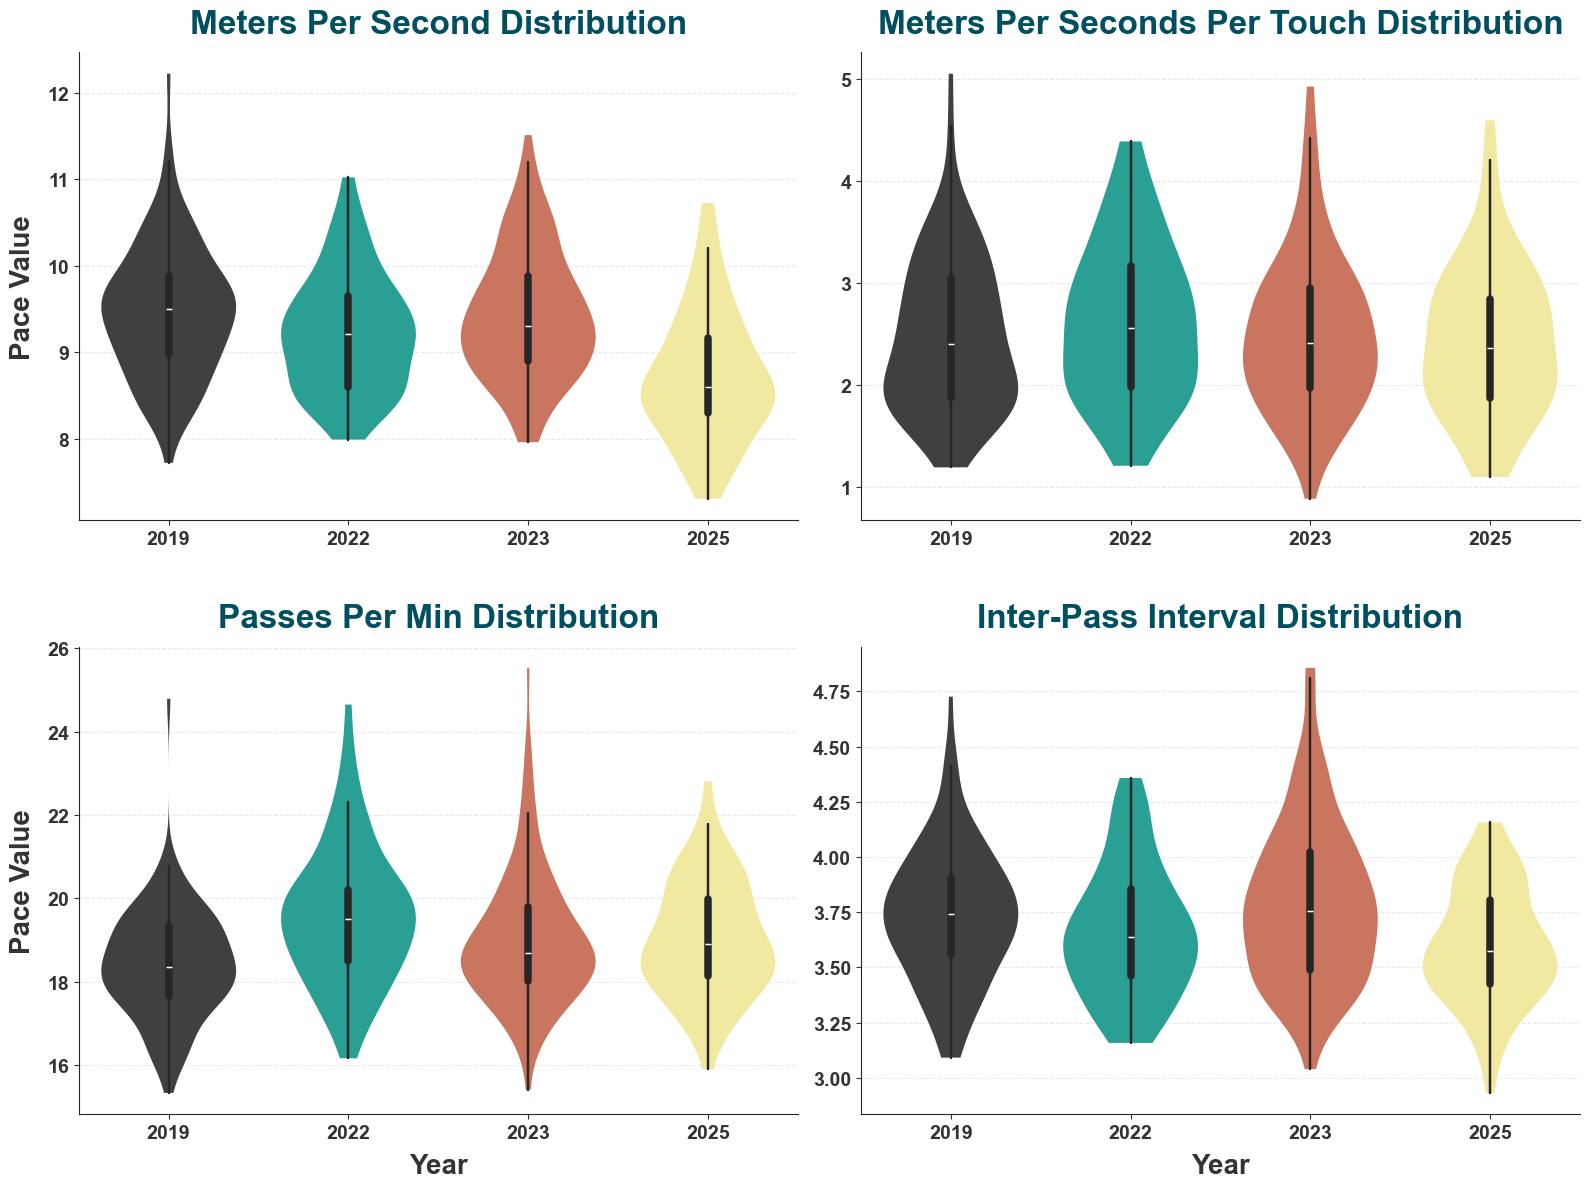

Tempo Descriptive Statistics by Year and Method

[2019]
--------------------------------------------------------------------------------

  Method: meters_per_second
    N:         104
    Mean:      9.4667
    Std:       0.7559
    Min:       7.7226
    25%:       8.9786
    Median:    9.4946
    75%:       9.8823
    Max:       12.2174
    Skewness:  0.4996
    Kurtosis:  0.8986

  Method: meters_per_seconds_per_touch
    N:         104
    Mean:      2.4829
    Std:       0.7523
    Min:       1.1933
    25%:       1.8767
    Median:    2.4022
    75%:       3.0506
    Max:       5.0505
    Skewness:  0.7121
    Kurtosis:  0.3700

  Method: passes_per_min
    N:         104
    Mean:      18.4178
    Std:       1.3167
    Min:       15.3333
    25%:       17.6540
    Median:    18.3555
    75%:       19.3300
    Max:       24.7862
    Skewness:  0.8876
    Kurtosis:  4.2322

  Method: time_to_pass
    N:         104
    Mean:      3.7378
    Std:       0.3052
    Min:       3.0917
 

In [ ]:
from collections import abc
import seaborn as sns
import scipy.stats as stats
sns.set_style("whitegrid")
sns.set_palette("husl")

years = sorted(lmm['year'].unique())
methods = sorted(lmm['method'].unique())

# 设置颜色方案
colors = sns.color_palette("husl", n_colors=len(methods))
year_colors = sns.color_palette("husl", n_colors=len(years))

# # ==================== 图1: Histogram + KDE ====================
# fig1, axes1 = plt.subplots(2, 2, figsize=(16, 12))
# axes1 = axes1.flatten()

# for idx, year in enumerate(years):
#     ax = axes1[idx]
#     year_data = lmm[lmm['year'] == year]
    
#     for i, method in enumerate(methods):
#         method_data = year_data[year_data['method'] == method]['tempo']
        
#         # Plot histogram
#         ax.hist(method_data, bins=30, alpha=0.3, color=colors[i], 
#                 label=method, density=True, edgecolor='black', linewidth=0.5)
        
#         # Overlay KDE curve
#         if len(method_data) > 1:
#             kde = stats.gaussian_kde(method_data.dropna())
#             x_range = np.linspace(method_data.min(), method_data.max(), 200)
#             ax.plot(x_range, kde(x_range), color=colors[i], linewidth=2.5)
    
#     ax.set_title(f'{year} Tempo Distribution (Histogram + KDE)', fontsize=14, fontweight='bold')
#     ax.set_xlabel('Tempo Value', fontsize=12)
#     ax.set_ylabel('Density', fontsize=12)
#     ax.legend(title='Method', fontsize=9, title_fontsize=10)
#     ax.grid(True, alpha=0.3)

# plt.tight_layout()
# plt.savefig('tempo_histogram_kde.png', dpi=300, bbox_inches='tight')
# plt.show()

# ==================== 图2: Violin Plot (按方法分面) 
with sns.axes_style("ticks"):
    fig2, axes2 = plt.subplots(2, 2, figsize=(16, 12))
    axes2 = axes2.flatten()

    clashing_colors = ["#404040", "#16b3a4", "#dc6a4d", "#fff493"]

    for idx, method in enumerate(methods):
        ax = axes2[idx]
        method_data = lmm[lmm["method"] == method].copy()

        method_data["year"] = pd.Categorical(
            method_data["year"], categories=years, ordered=True
        )

        sns.violinplot(
            data=method_data,
            x="year",
            y="tempo",
            hue="year",
            palette=clashing_colors,
            ax=ax,
            linewidth=1.2,
            inner="box",
            dodge=False,
            legend=False,
            cut=0,
            width=0.75,
        )

        for collection in ax.collections:
            collection.set_edgecolor("none")
            collection.set_linewidth(0)

        sns.despine(ax=ax)

        ax.grid(True, linestyle="--", alpha=0.4, axis="y", zorder=0)

        if method == "time_to_pass":
            title_text = "Inter-Pass Interval Distribution"
        else:
            title_text = f'{method.replace("_", " ").title()} Distribution'

        ax.set_title(
            title_text, fontsize=24, fontweight="bold", pad=14, color="#004F60"
        )

        # 判断当前子图的行和列 (2x2 矩阵中，idx 0,1 是第一排；0,2 是第一列)
        is_first_row = idx < 2  # 0, 1 是第一排
        is_second_col = idx % 2 == 1  # 1, 3 是第二列

        # 横坐标 (X轴)：如果是第一排，不显示 'Year' 文本
        if is_first_row:
            ax.set_xlabel("", fontsize=20)  # 设为空字符串
        else:
            ax.set_xlabel(
                "Year", fontsize=20, fontweight="bold", labelpad=8, color="#333333"
            )

        # 纵坐标 (Y轴)：如果是第二列，不显示 'Pace Value' 文本
        if is_second_col:
            ax.set_ylabel("", fontsize=20)  
        else:
            ax.set_ylabel(
                "Pace Value",
                fontsize=20,
                fontweight="bold",
                labelpad=8,
                color="#333333",
            )

        plt.setp(
            ax.get_xticklabels(), fontsize=20, fontweight="bold", color="#333333"
        )
        plt.setp(
            ax.get_yticklabels(), fontsize=20, fontweight="bold", color="#333333"
        )

        ax.tick_params(colors="#333333", labelsize=14)
        ax.set_xticklabels(years)

    # 2. 调整布局与行距
    plt.tight_layout(h_pad=4.0) 

    plt.savefig("tempo_violin.png", dpi=300, bbox_inches="tight")
    plt.show()

    
# ==================== Descriptive Statistics ====================
print("="*80)
print("Tempo Descriptive Statistics by Year and Method")
print("="*80)

for year in years:
    print(f"\n[{year}]")
    print("-"*80)
    year_data = lmm[lmm['year'] == year]
    
    for method in methods:
        method_data = year_data[year_data['method'] == method]['tempo']
        
        print(f"\n  Method: {method}")
        print(f"    N:         {len(method_data)}")
        print(f"    Mean:      {method_data.mean():.4f}")
        print(f"    Std:       {method_data.std():.4f}")
        print(f"    Min:       {method_data.min():.4f}")
        print(f"    25%:       {method_data.quantile(0.25):.4f}")
        print(f"    Median:    {method_data.median():.4f}")
        print(f"    75%:       {method_data.quantile(0.75):.4f}")
        print(f"    Max:       {method_data.max():.4f}")
        print(f"    Skewness:  {method_data.skew():.4f}")
        print(f"    Kurtosis:  {method_data.kurtosis():.4f}")

# ==================== Summary Table ====================
stats_list = []
for year in years:
    year_data = lmm[lmm['year'] == year]
    for method in methods:
        method_data = year_data[year_data['method'] == method]['tempo']
        stats_list.append({
            'Year': year,
            'Method': method,
            'N': len(method_data),
            'Mean': method_data.mean(),
            'Std': method_data.std(),
            'Min': method_data.min(),
            'Median': method_data.median(),
            'Max': method_data.max()
        })

stats_df = pd.DataFrame(stats_list)
print("\n" + "="*80)
print("Summary Statistics Table")
print("="*80)
print(stats_df.to_string(index=False))

In [19]:
overall_stats_list = []

for method in methods:
    method_data = lmm[lmm['method'] == method]['tempo']
    overall_stats_list.append({
        'Method': method,
        'N': len(method_data),
        'Mean': method_data.mean(),
        'Std': method_data.std(),
        'Min': method_data.min(),
        'Median': method_data.median(),
        'Max': method_data.max()
    })

overall_stats_df = pd.DataFrame(overall_stats_list)

print("\n" + "="*80)
print("Overall Summary Statistics Table (All Years)")
print("="*80)
print(overall_stats_df.to_string(index=False))



Overall Summary Statistics Table (All Years)
                      Method   N      Mean      Std       Min    Median       Max
           meters_per_second 356  9.284991 0.783650  7.308593  9.242582 12.217435
meters_per_seconds_per_touch 356  2.508099 0.759386  0.886337  2.432799  5.050529
              passes_per_min 356 18.929418 1.533518 15.333284 18.733765 25.526727
                time_to_pass 356  3.717221 0.325504  2.931921  3.678132  4.856034
